<a href="https://colab.research.google.com/github/pelipelipelipelipeli/Monte_Carlo_Stock_Simulation/blob/main/Monte_Carlo_Stock_Simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [30]:

import yfinance as yf
import pandas as pd
from datetime import datetime

print("Today's date:", datetime.now().date())
print("yfinance version:", yf.__version__)

test = yf.download(
    "AAPL",
    period="1mo",
    interval="1d",
    auto_adjust=True,
    progress=False,
    multi_level_index=False
)

print("\nRows downloaded:", len(test))

if test.empty:
    print("RESULT: No data received.")
else:
    print("First date:", test.index.min())
    print("Latest date:", test.index.max())
    display(test.tail())

Today's date: 2026-10-25
yfinance version: 0.2.66

Rows downloaded: 22
First date: 2026-09-24 00:00:00
Latest date: 2026-10-23 00:00:00


,Close,High,Low,Open,Volume
Date,,,,,
2026-10-19,342.940002,346.000000,340.119995,340.779999,34573200
2026-10-20,339.500000,343.059998,338.700012,339.859985,35851400
2026-10-21,343.989990,345.250000,338.829987,339.359985,35614100
2026-10-22,348.220001,348.359985,342.279999,344.940002,46898900
2026-10-23,347.730011,351.730011,345.750000,349.119995,39496500


In [31]:

# STEP 1: REFRESH ALL STOCK DATA

import yfinance as yf
import pandas as pd
from datetime import datetime

stocks = {
    "Apple": "AAPL",
    "Microsoft": "MSFT",
    "Bank Central Asia": "BBCA.JK",
    "Bank Rakyat Indonesia": "BBRI.JK"
}

price_data = {}

for name, ticker in stocks.items():
    print(f"\nDownloading {name} ({ticker})...")

    data = yf.download(
        ticker,
        period="5y",
        interval="1d",
        auto_adjust=True,
        progress=False,
        multi_level_index=False
    )

    if data.empty:
        print("No data found for", ticker)
        continue

    close = data["Close"].dropna()

    price_data[name] = close

    print("Latest date:", close.index.max().date())
    print("Number of rows:", len(close))

print("\nRefresh finished.")


Latest date: 2026-10-23
Number of rows: 1255

Latest date: 2026-10-23
Number of rows: 1255

Latest date: 2026-10-23
Number of rows: 1200

Latest date: 2026-10-23
Number of rows: 1200

Refresh finished.


In [33]:

# STEP 9: CALCULATE RETURNS AND VOLATILITY

# Combine downloaded stock prices
prices = pd.concat(price_data, axis=1).sort_index()

# Calculate daily percentage returns
daily_returns = prices.pct_change(fill_method=None).dropna(how="all")

# Calculate annualized average returns
annual_returns = daily_returns.mean() * 252

# Calculate annualized volatility
annual_volatility = daily_returns.std() * np.sqrt(252)

# Show the LATEST stock prices
print("LATEST 5 STOCK PRICES")
display(prices.tail())

# Show the LATEST daily returns
print("\nLATEST 5 DAILY RETURNS")
display(daily_returns.tail())

# Show the latest date for each stock
print("\nLATEST AVAILABLE DATE FOR EACH STOCK")
for stock in prices.columns:
    latest_date = prices[stock].last_valid_index()
    print(stock, ":", latest_date.date() if latest_date is not None else "No data")

# Display annualized returns
print("\nANNUALIZED AVERAGE RETURNS")
display((annual_returns * 100).round(2).astype(str) + "%")

# Display annualized volatility
print("\nANNUALIZED VOLATILITY")
display((annual_volatility * 100).round(2).astype(str) + "%")

LATEST 5 STOCK PRICES


,Apple,Microsoft,Bank Central Asia,Bank Rakyat Indonesia
Date,,,,
2026-10-19,342.940002,533.520020,4820.0,2540.0
2026-10-20,339.500000,531.869995,5200.0,2790.0
2026-10-21,343.989990,532.950012,5275.0,2810.0
2026-10-22,348.220001,521.080017,5175.0,2900.0
2026-10-23,347.730011,524.510010,5025.0,2910.0



LATEST 5 DAILY RETURNS


,Apple,Microsoft,Bank Central Asia,Bank Rakyat Indonesia
Date,,,,
2026-10-19,-0.001514,0.008449,-0.068599,-0.037879
2026-10-20,-0.010031,-0.003093,0.078838,0.098425
2026-10-21,0.013225,0.002031,0.014423,0.007168
2026-10-22,0.012297,-0.022272,-0.018957,0.032028
2026-10-23,-0.001407,0.006582,-0.028986,0.003448



LATEST AVAILABLE DATE FOR EACH STOCK
Apple : 2026-10-23
Microsoft : 2026-10-23
Bank Central Asia : 2026-10-23
Bank Rakyat Indonesia : 2026-10-23

ANNUALIZED AVERAGE RETURNS


,0
Apple,26.3%
Microsoft,17.86%
Bank Central Asia,1.01%
Bank Rakyat Indonesia,5.26%



ANNUALIZED VOLATILITY


,0
Apple,27.96%
Microsoft,28.41%
Bank Central Asia,26.07%
Bank Rakyat Indonesia,28.88%


In [34]:

# STEP 10: MONTE CARLO STOCK PRICE SIMULATION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Simulation settings
number_of_simulations = 10000
forecast_days = 252  # Approximately 1 trading year

# Store simulation results
simulation_results = {}

# Set a random seed so results are reproducible
np.random.seed(42)

for stock in prices.columns:

    # Get historical daily returns for this stock
    stock_returns = daily_returns[stock].dropna()

    # Calculate historical daily average return and volatility
    daily_mean = stock_returns.mean()
    daily_std = stock_returns.std()

    # Get the latest available stock price
    starting_price = prices[stock].dropna().iloc[-1]

    # Generate random daily returns
    random_returns = np.random.normal(
        daily_mean,
        daily_std,
        size=(forecast_days, number_of_simulations)
    )

    # Simulate future stock prices
    price_paths = np.zeros(
        (forecast_days + 1, number_of_simulations)
    )

    price_paths[0] = starting_price

    for day in range(1, forecast_days + 1):
        price_paths[day] = (
            price_paths[day - 1] * (1 + random_returns[day - 1])
        )

    # Save results for each stock
    simulation_results[stock] = price_paths

print("Step 10 completed!")
print("Simulations per stock:", number_of_simulations)
print("Forecast period:", forecast_days, "trading days")

for stock, paths in simulation_results.items():
    print(
        stock,
        "| Starting price:", round(paths[0, 0], 2),
        "| Simulated paths:", paths.shape[1]
    )

Step 10 completed!
Simulations per stock: 10000
Forecast period: 252 trading days
Apple | Starting price: 347.73 | Simulated paths: 10000
Microsoft | Starting price: 524.51 | Simulated paths: 10000
Bank Central Asia | Starting price: 5025.0 | Simulated paths: 10000
Bank Rakyat Indonesia | Starting price: 2910.0 | Simulated paths: 10000


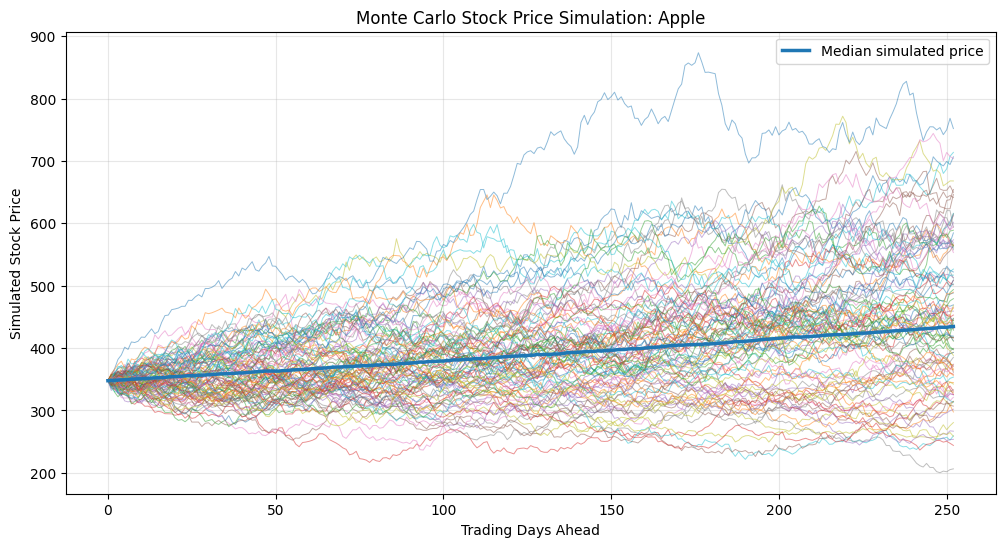

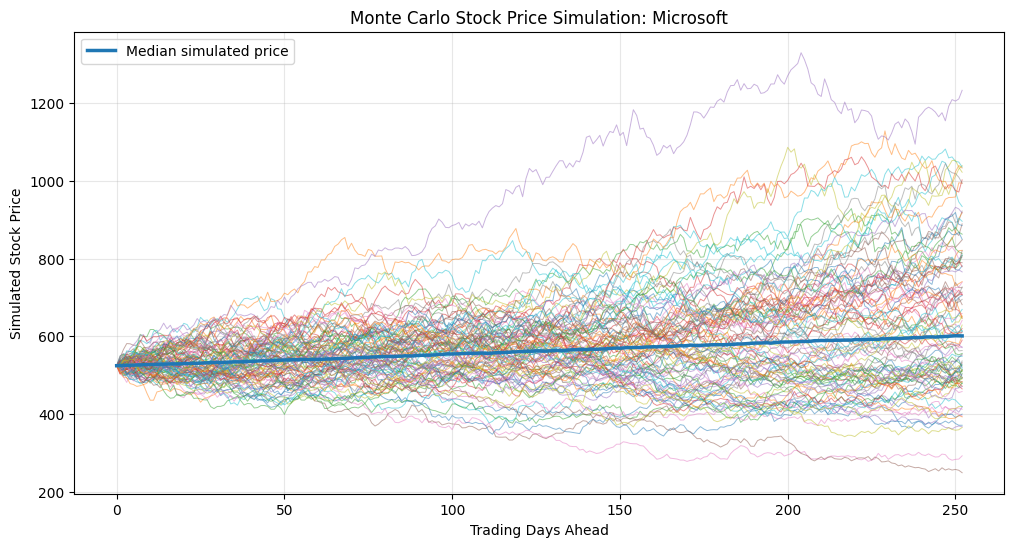

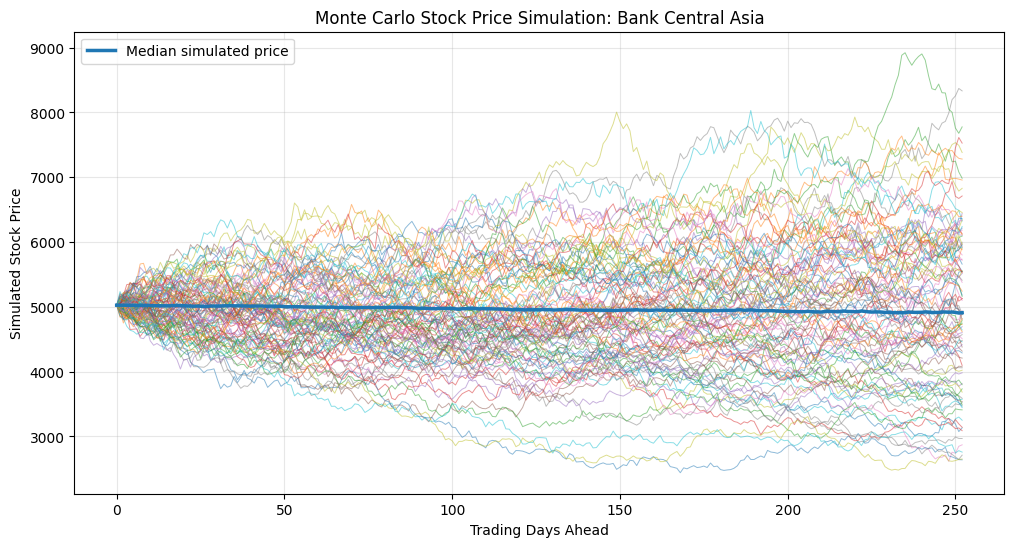

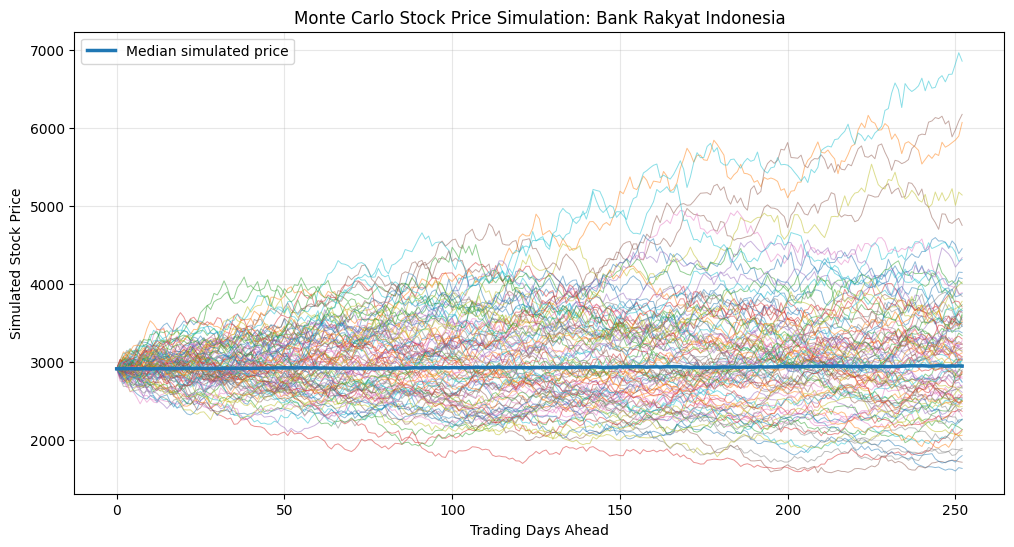

In [36]:

# STEP 11: VISUALIZE MONTE CARLO SIMULATIONS

for stock, paths in simulation_results.items():

    plt.figure(figsize=(12, 6))

    # Plot 100 sample paths so the chart stays readable
    plt.plot(paths[:, :100], linewidth=0.7, alpha=0.5)

    # Plot the median simulated price
    median_path = np.median(paths, axis=1)
    plt.plot(
        median_path,
        linewidth=2.5,
        label="Median simulated price"
    )

    plt.title(f"Monte Carlo Stock Price Simulation: {stock}")
    plt.xlabel("Trading Days Ahead")
    plt.ylabel("Simulated Stock Price")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

In [37]:

# CHECK THE MEDIAN PRICE PATH

for stock, paths in simulation_results.items():
    median_path = np.median(paths, axis=1)

    print(f"\n{stock}")
    print("Starting median:", round(median_path[0], 2))
    print("Median after 1 month:", round(median_path[21], 2))
    print("Median after 6 months:", round(median_path[126], 2))
    print("Median after 1 year:", round(median_path[-1], 2))



Apple
Starting median: 347.73
Median after 1 month: 354.67
Median after 6 months: 388.49
Median after 1 year: 434.64

Microsoft
Starting median: 524.51
Median after 1 month: 529.98
Median after 6 months: 562.58
Median after 1 year: 601.14

Bank Central Asia
Starting median: 5025.0
Median after 1 month: 5013.3
Median after 6 months: 4953.47
Median after 1 year: 4909.16

Bank Rakyat Indonesia
Starting median: 2910.0
Median after 1 month: 2916.52
Median after 6 months: 2927.12
Median after 1 year: 2945.15


In [38]:

# STEP 12: MONTE CARLO RESULTS SUMMARY

results_summary = []

for stock, paths in simulation_results.items():

    # Final simulated price from all 10,000 simulations
    final_prices = paths[-1, :]

    # Latest historical price
    starting_price = prices[stock].dropna().iloc[-1]

    # Calculate ending price statistics
    median_price = np.median(final_prices)
    average_price = np.mean(final_prices)
    percentile_5 = np.percentile(final_prices, 5)
    percentile_95 = np.percentile(final_prices, 95)

    # Percentage of simulations ending below starting price
    probability_loss = np.mean(final_prices < starting_price) * 100

    # Store the results
    results_summary.append({
        "Stock": stock,
        "Latest Price": starting_price,
        "Median Ending Price": median_price,
        "Average Ending Price": average_price,
        "5th Percentile": percentile_5,
        "95th Percentile": percentile_95,
        "Probability of Loss (%)": probability_loss
    })

# Create and display the table
results_df = pd.DataFrame(results_summary)

# Round price values for readability
price_columns = [
    "Latest Price",
    "Median Ending Price",
    "Average Ending Price",
    "5th Percentile",
    "95th Percentile"
]

results_df[price_columns] = results_df[price_columns].round(2)
results_df["Probability of Loss (%)"] = (
    results_df["Probability of Loss (%)"].round(2)
)

display(results_df)

,Stock,Latest Price,Median Ending Price,Average Ending Price,5th Percentile,95th Percentile,Probability of Loss (%)
0,Apple,347.73,434.64,451.21,274.68,685.64,21.60
1,Microsoft,524.51,601.14,627.02,379.40,958.87,31.40
2,Bank Central Asia,5025.00,4909.16,5077.67,3193.76,7535.50,53.38
3,Bank Rakyat Indonesia,2910.00,2945.15,3063.82,1820.91,4709.93,48.14


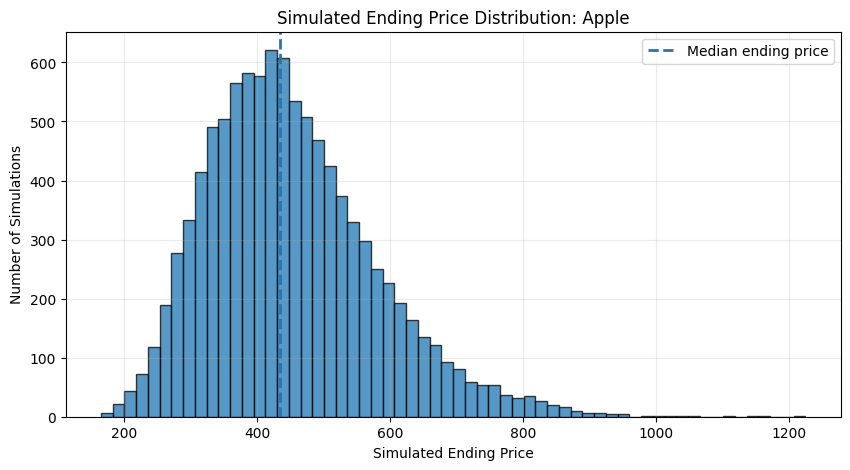

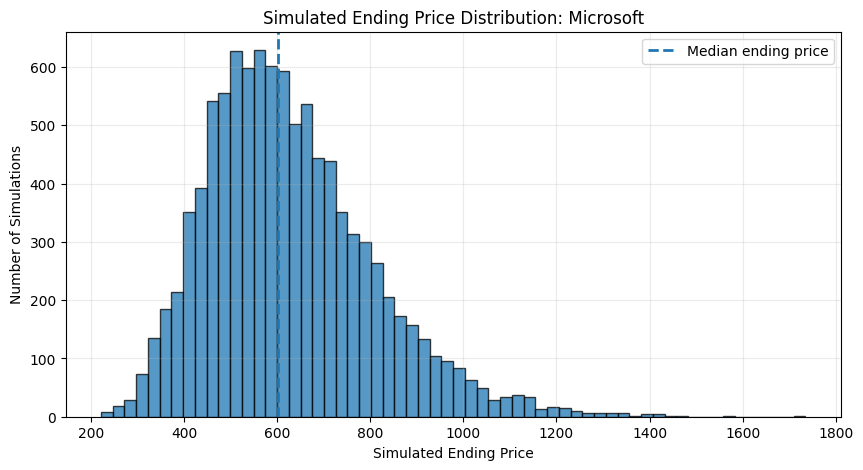

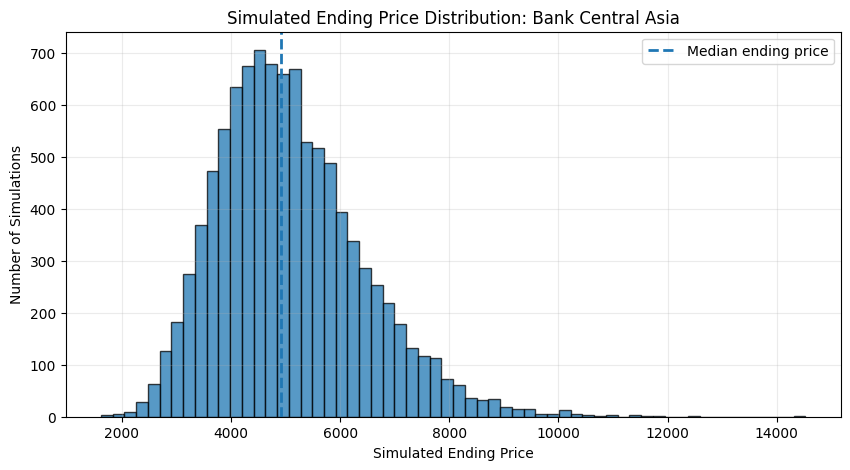

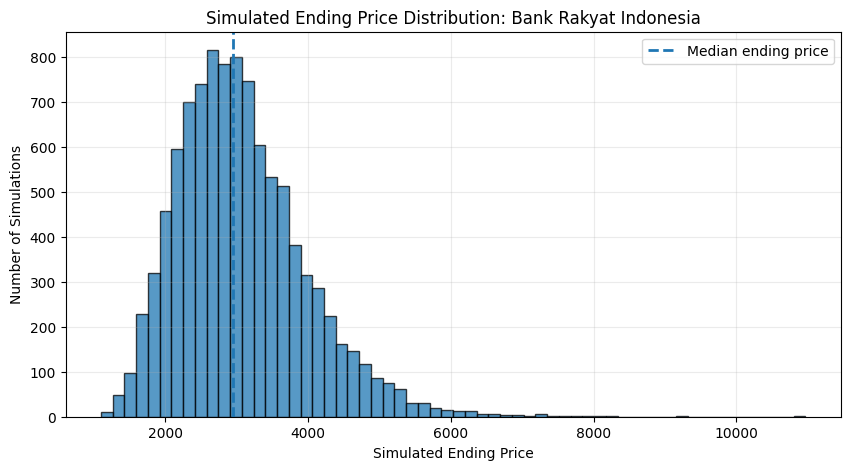

In [39]:

# STEP 13: DISTRIBUTION OF SIMULATED ENDING PRICES

for stock, paths in simulation_results.items():

    final_prices = paths[-1, :]

    plt.figure(figsize=(10, 5))

    plt.hist(final_prices, bins=60, edgecolor="black", alpha=0.75)

    plt.axvline(
        np.median(final_prices),
        linestyle="--",
        linewidth=2,
        label="Median ending price"
    )

    plt.title(f"Simulated Ending Price Distribution: {stock}")
    plt.xlabel("Simulated Ending Price")
    plt.ylabel("Number of Simulations")
    plt.legend()
    plt.grid(True, alpha=0.25)
    plt.show()

In [40]:

# STEP 14: RISK ANALYSIS

risk_analysis = []

for _, row in results_df.iterrows():

    starting_price = row["Latest Price"]
    median_price = row["Median Ending Price"]
    low_price = row["5th Percentile"]
    high_price = row["95th Percentile"]
    loss_probability = row["Probability of Loss (%)"]

    median_return = (
        (median_price / starting_price) - 1
    ) * 100

    downside_from_start = (
        (low_price / starting_price) - 1
    ) * 100

    upside_from_start = (
        (high_price / starting_price) - 1
    ) * 100

    risk_analysis.append({
        "Stock": row["Stock"],
        "Median Simulated Return (%)": round(median_return, 2),
        "5th Percentile Return (%)": round(downside_from_start, 2),
        "95th Percentile Return (%)": round(upside_from_start, 2),
        "Probability of Loss (%)": round(loss_probability, 2)
    })

risk_df = pd.DataFrame(risk_analysis)

display(risk_df)

,Stock,Median Simulated Return (%),5th Percentile Return (%),95th Percentile Return (%),Probability of Loss (%)
0,Apple,24.99,-21.01,97.18,21.60
1,Microsoft,14.61,-27.67,82.81,31.40
2,Bank Central Asia,-2.31,-36.44,49.96,53.38
3,Bank Rakyat Indonesia,1.21,-37.43,61.85,48.14
